# 07. ROC-AUC và AP theo nhóm khi chuyển nguồn dữ liệu

Chạy lần lượt từ trên xuống. Trong VS Code, chọn kernel `.venv312\Scripts\python.exe` của repository.

**Mục tiêu:** đối chiếu khả năng xếp hạng của LR và XGBoost trên NHANES (outer-fold OOF) và BRFSS 2017 (kiểm định ngoài), theo giới tính, chủng tộc, tuổi và BMI.

- Dùng điểm dự đoán liên tục, không đọc cột nhãn dự đoán sau ngưỡng.
- AP là Average Precision từng nhóm. Macro AP là trung bình cộng AP của các nhóm định trước thuộc cùng một đặc trưng.
- Chênh lệch hiệu năng là dấu hiệu để nghiên cứu tiếp, chưa chứng minh nguyên nhân thiên kiến.
- Notebook tạo ước lượng điểm. CI và phân tích nguyên nhân là bước tiếp theo. Không huấn luyện hoặc hiệu chỉnh mô hình tại đây.

## Bước 1 — Chuẩn bị thư viện và đường dẫn

Cell này tìm thư mục dự án để notebook chạy được từ thư mục repository hoặc notebooks. Kiểm tra Python in ra thuộc môi trường `.venv312`. Dùng lại hàm chia nhóm từ `src/utils.py` để giữ định nghĩa thống nhất.

In [18]:
from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score, average_precision_score

project_dir = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'data/processed').is_dir() and (p / 'src').is_dir()
)
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.utils import get_fairness_groups, get_fairness_group_specs

MODELS = ['XGBoost', 'LR']
INTERNAL_RUN = '3d15f3dbb58256ec'
EXTERNAL_RUN = '54c463bbe9079503'
output_dir = project_dir / 'results/nhanes_to_brfss/auc_ap_dataset_shift'

print('Python:', sys.executable)
print('Project:', project_dir)
print('Định nghĩa nhóm:', get_fairness_group_specs()[0])
figures_dir = project_dir / 'results/nhanes_to_brfss/figures/auc_ap_dataset_shift' / EXTERNAL_RUN


Python: d:\nckh\diabetes-ml-fairness\.venv312\Scripts\python.exe
Project: d:\nckh\diabetes-ml-fairness\diabetes-project
Định nghĩa nhóm: {'race_ethnicity': ['White NH', 'Black NH', 'Hispanic', 'Other'], 'age': ['18-39', '40-59', '60+'], 'bmi': ['Underweight', 'Normal', 'Overweight', 'Obese']}


## Bước 2 — Xác định đúng nguồn dự đoán

**NHANES:** `results/nhanes_to_brfss/tuning/3d15f3dbb58256ec/oof_*.parquet`, mỗi người có một dự đoán outer-fold từ mô hình không học hoặc tuning trên người đó.

**BRFSS 2017:** dự đoán ngoài thuộc final run `54c463bbe9079503`. Hai ID khác nhau vì một ID thuộc giai đoạn nested CV, một ID thuộc giai đoạn mô hình cuối.

Mô hình `.joblib` hiện có thuộc run `9dafe348742a3e02`. Notebook này phân tích các dự đoán cũ đã lưu, **không gán chúng cho file mô hình hiện tại**. So sánh nội bộ/ngoài đánh giá quy trình học, không phải cùng một mô hình đã fit: OOF đến từ các mô hình vòng ngoài, BRFSS từ mô hình cuối.

Không dùng `final_development/*/development_oof.parquet` làm đánh giá nội bộ độc lập, vì file đó phục vụ phát triển ngưỡng sau khi chọn cấu hình.

In [19]:
source_paths = {
    'nhanes_processed': project_dir / 'data/processed/nhanes_2015_2018.parquet',
    'external_manifest': project_dir / f'results/nhanes_to_brfss/external_validation/{EXTERNAL_RUN}/manifest.json',
    'group_definition': project_dir / 'src/utils.py',
}
for model in MODELS:
    source_paths[f'internal_{model}'] = project_dir / f'results/nhanes_to_brfss/tuning/{INTERNAL_RUN}/oof_{model}.parquet'
    source_paths[f'external_{model}'] = project_dir / f'results/nhanes_to_brfss/external_validation/{EXTERNAL_RUN}/brfss_2017_{model}_predictions.parquet'

for name, path in source_paths.items():
    if not path.is_file():
        raise FileNotFoundError(f'{name}: {path}')

external_manifest = json.loads(source_paths['external_manifest'].read_text(encoding='utf-8'))
assert external_manifest['final_run_id'] == EXTERNAL_RUN
display(pd.DataFrame([{'source': k, 'path': str(v.relative_to(project_dir))}
                      for k, v in source_paths.items()]))

,source,path
0,nhanes_processed,data\processed\nhanes_2015_2018.parquet
1,external_manifest,results\external_validation\54c463bbe9079503\m...
2,group_definition,src\utils.py
3,internal_XGBoost,results\tuning\3d15f3dbb58256ec\oof_XGBoost.pa...
4,external_XGBoost,results\external_validation\54c463bbe9079503\b...
5,internal_LR,results\tuning\3d15f3dbb58256ec\oof_LR.parquet
6,external_LR,results\external_validation\54c463bbe9079503\b...


## Bước 3 — Nối nhóm với dự đoán và kiểm tra dữ liệu

OOF NHANES chỉ có định danh và điểm; nối với dữ liệu đã xử lý bằng `SEQN` và `cycle`, không theo thứ tự dòng. BRFSS đã có các đặc trưng nhóm.

Sau cell này, mỗi bảng có `y_true`, `score`, `sex`, `race_ethnicity`, `age`, `bmi`. Các kiểm tra đảm bảo không mất người, không nối nhầm nhãn, điểm hữu hạn và hai mô hình đánh giá cùng những người.

In [20]:
nhanes = pd.read_parquet(source_paths['nhanes_processed'])
group_cols = ['sex', 'race_ethnicity', 'age', 'bmi']
evaluation_data = {}
cohort_ids = {}

for model in MODELS:
    oof = pd.read_parquet(source_paths[f'internal_{model}'])
    assert oof['run_id'].eq(INTERNAL_RUN).all()
    assert set(oof['outer_fold'].unique()) == {1, 2, 3, 4, 5}
    internal = oof.merge(
        nhanes[['SEQN', 'cycle', 'diabetes_label'] + group_cols],
        on=['SEQN', 'cycle'], how='left', validate='one_to_one', indicator=True,
    )
    assert len(internal) == len(nhanes) == 10832
    assert internal['_merge'].eq('both').all()
    assert internal['y_true'].eq(internal['diabetes_label']).all()

    external = pd.read_parquet(source_paths[f'external_{model}'])
    assert external['source_row_id'].is_unique
    assert external['year'].eq(2017).all()
    assert len(external) == 449219
    external = external.rename(columns={'diabetes_label': 'y_true', 'probability': 'score'})

    cohort_ids[('NHANES_OOF', model)] = set(zip(internal['SEQN'], internal['cycle']))
    cohort_ids[('BRFSS_2017', model)] = set(external['source_row_id'])
    for dataset, frame in [('NHANES_OOF', internal), ('BRFSS_2017', external)]:
        frame = frame[['y_true', 'score'] + group_cols].reset_index(drop=True).copy()
        assert frame['y_true'].notna().all() and frame['y_true'].isin([0, 1]).all()
        assert np.isfinite(frame['score'].to_numpy(dtype=float)).all()
        evaluation_data[(dataset, model)] = frame

for dataset in ['NHANES_OOF', 'BRFSS_2017']:
    assert cohort_ids[(dataset, 'LR')] == cohort_ids[(dataset, 'XGBoost')]

display(pd.DataFrame([
    {'dataset': dataset, 'model': model, 'n': len(frame),
     'n_positive': int(frame['y_true'].sum()), 'positive_rate': frame['y_true'].mean()}
    for (dataset, model), frame in evaluation_data.items()
]).round(4))

,dataset,model,n,n_positive,positive_rate
0,NHANES_OOF,XGBoost,10832,2274,0.2099
1,BRFSS_2017,XGBoost,449219,60440,0.1345
2,NHANES_OOF,LR,10832,2274,0.2099
3,BRFSS_2017,LR,449219,60440,0.1345


## Bước 4 — Tính ROC-AUC và AP toàn tập, theo nhóm

- ROC-AUC đánh giá thứ tự điểm giữa người có và không có nhãn bệnh.
- AP tóm tắt precision–recall bằng `average_precision_score`, không phải diện tích PR tính bằng quy tắc hình thang.
- Không cần ngưỡng Youden. Điểm đưa vào là `score` liên tục.
- Báo cáo tỷ lệ bệnh cùng AP vì AP phụ thuộc tỷ lệ lớp dương.
- Giữ cả nhóm thiếu dữ liệu và BMI thiếu cân trong mô tả. Nếu thiếu một lớp, để chỉ số là NA và ghi trạng thái, không gán 0.

Khi rerun cell này sau khi chỉnh hàm, kết quả sẽ được tính lại từ các dự đoán đã đọc.

In [21]:
def summarize_scores(frame):
    y = frame['y_true'].to_numpy(dtype=int)
    score = frame['score'].to_numpy(dtype=float)
    valid = np.unique(y).size == 2
    return {
        'n': len(y), 'n_positive': int(y.sum()),
        'n_negative': int(len(y) - y.sum()),
        'positive_rate': float(y.mean()) if len(y) else np.nan,
        'roc_auc': roc_auc_score(y, score) if valid else np.nan,
        'ap': average_precision_score(y, score) if valid else np.nan,
        'status': 'ok' if valid else 'Không đủ hai lớp',
    }

def evaluate_dataset(frame, dataset, model):
    groups, specs = get_fairness_groups(frame)
    assert frame['sex'].dropna().isin([1, 2]).all()
    groups['sex'] = frame['sex'].map({1: 'Nam', 2: 'Nữ'}).astype('string').fillna('Missing')
    specs = {'sex': ['Nam', 'Nữ'], **specs}
    rows = [{'dataset': dataset, 'model': model, 'attribute': 'overall',
             'group': 'All', **summarize_scores(frame)}]
    for attribute, labels in specs.items():
        for label in labels + ['Missing']:
            subset = frame.loc[groups[attribute].eq(label)]
            rows.append({'dataset': dataset, 'model': model, 'attribute': attribute,
                         'group': label, **summarize_scores(subset)})
    return pd.DataFrame(rows)

metrics = pd.concat([
    evaluate_dataset(frame, dataset, model)
    for (dataset, model), frame in evaluation_data.items()
], ignore_index=True)

for (dataset, model), block in metrics.groupby(['dataset', 'model']):
    n_total = int(block.loc[block['attribute'].eq('overall'), 'n'].iloc[0])
    for attribute in ['sex', 'age', 'bmi', 'race_ethnicity']:
        assert block.loc[block['attribute'].eq(attribute), 'n'].sum() == n_total

display(metrics.query("attribute == 'overall'").round(4))
display(metrics.query("attribute == 'age' and group != 'Missing'").round(4))

,dataset,model,attribute,group,n,n_positive,n_negative,positive_rate,roc_auc,ap,status
0,NHANES_OOF,XGBoost,overall,All,10832,2274,8558,0.2099,0.7999,0.4784,ok
18,BRFSS_2017,XGBoost,overall,All,449219,60440,388779,0.1345,0.7691,0.3218,ok
36,NHANES_OOF,LR,overall,All,10832,2274,8558,0.2099,0.7950,0.4617,ok
54,BRFSS_2017,LR,overall,All,449219,60440,388779,0.1345,0.7722,0.3293,ok


,dataset,model,attribute,group,n,n_positive,n_negative,positive_rate,roc_auc,ap,status
9,NHANES_OOF,XGBoost,age,18-39,3720,170,3550,0.0457,0.7688,0.1664,ok
10,NHANES_OOF,XGBoost,age,40-59,3339,684,2655,0.2049,0.7032,0.3759,ok
11,NHANES_OOF,XGBoost,age,60+,3773,1420,2353,0.3764,0.6753,0.5314,ok
27,BRFSS_2017,XGBoost,age,18-39,99769,2300,97469,0.0231,0.7263,0.0823,ok
28,BRFSS_2017,XGBoost,age,40-59,140691,16128,124563,0.1146,0.7357,0.2722,ok
29,BRFSS_2017,XGBoost,age,60+,208759,42012,166747,0.2012,0.6912,0.3464,ok
45,NHANES_OOF,LR,age,18-39,3720,170,3550,0.0457,0.7653,0.1578,ok
46,NHANES_OOF,LR,age,40-59,3339,684,2655,0.2049,0.7048,0.3781,ok
47,NHANES_OOF,LR,age,60+,3773,1420,2353,0.3764,0.6606,0.5098,ok
63,BRFSS_2017,LR,age,18-39,99769,2300,97469,0.0231,0.7279,0.0826,ok


### Biểu đồ đối chiếu ROC-AUC nội bộ và ngoài theo từng nhóm

Mỗi ô là một đặc trưng của một mô hình. Hai cột cạnh nhau biểu diễn **NHANES OOF** và **BRFSS 2017** của cùng nhóm. Giá trị trên đầu cột là ROC-AUC của nhóm đó.

- Xem nhóm nào có AUC ngoài thấp hơn nội bộ và mức không đồng đều giữa các nhóm.
- Trục ROC-AUC thống nhất 0–1. Đường 0,5 là mốc xếp hạng ngẫu nhiên.
- BMI thiếu cân được giữ để mô tả; macro AP chính ở Bước 6 vẫn chỉ dùng ba nhóm BMI chính.
- Mặc định không vẽ Missing. Đổi `SHOW_MISSING_AUC = True` nếu muốn xem. NA nghĩa là không đủ hai lớp để tính AUC.
- Đây là ước lượng điểm, chưa có CI. Chênh lệch cột chưa tự chứng minh ý nghĩa thống kê hoặc nguyên nhân bias.

Biểu đồ dùng `metrics` vừa tính ở trên, không cần chạy Bước 5 trước.

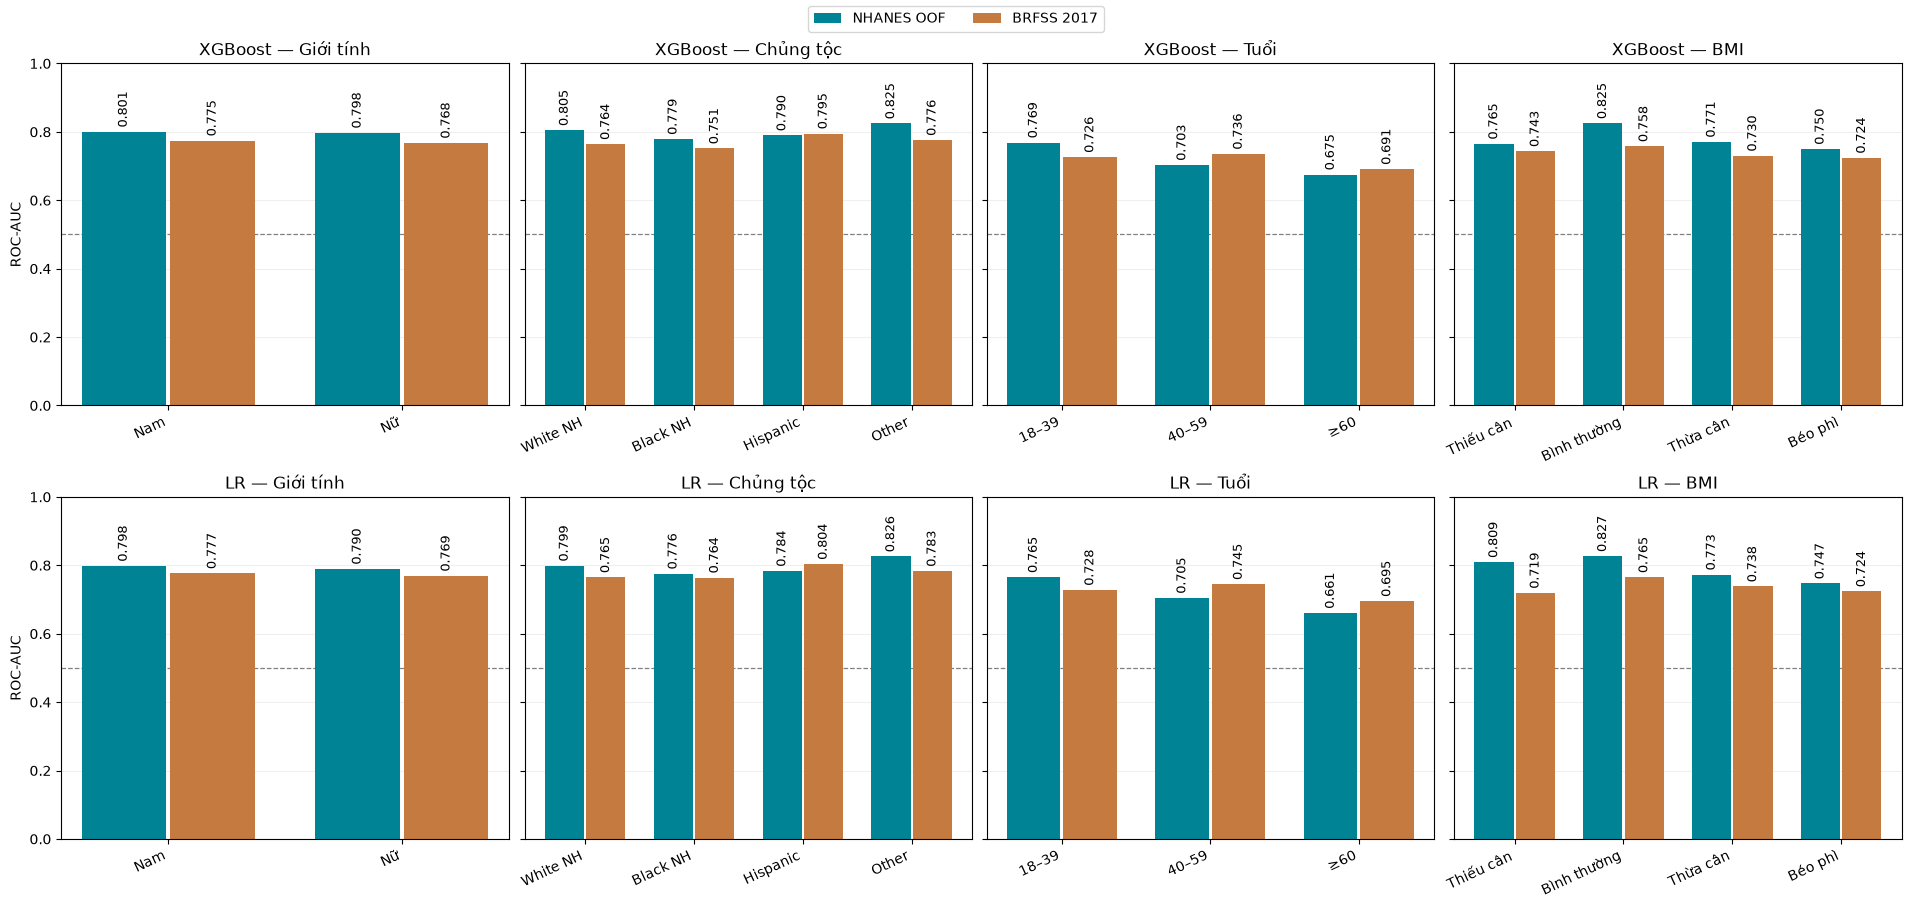

In [22]:
SHOW_MISSING_AUC = False

auc_specs, _ = get_fairness_group_specs()
auc_specs = {'sex': ['Nam', 'Nữ'], **auc_specs}
attribute_names = {
    'sex': 'Giới tính', 'race_ethnicity': 'Chủng tộc',
    'age': 'Tuổi', 'bmi': 'BMI',
}
group_names = {
    '18-39': '18–39', '40-59': '40–59', '60+': '≥60',
    'Underweight': 'Thiếu cân', 'Normal': 'Bình thường',
    'Overweight': 'Thừa cân', 'Obese': 'Béo phì', 'Missing': 'Thiếu dữ liệu',
}

auc_group_fig, auc_axes = plt.subplots(
    len(MODELS), len(auc_specs), figsize=(19, 4.5 * len(MODELS)),
    squeeze=False, sharey=True, constrained_layout=True,
)
for row, model in enumerate(MODELS):
    for col, (attribute, labels) in enumerate(auc_specs.items()):
        ax = auc_axes[row, col]
        labels = labels + (['Missing'] if SHOW_MISSING_AUC else [])
        block = metrics.loc[
            metrics['model'].eq(model) & metrics['attribute'].eq(attribute)
        ]
        assert not block.duplicated(['group', 'dataset']).any()
        auc_values = block.pivot(index='group', columns='dataset', values='roc_auc')
        auc_values = auc_values.reindex(labels)
        x = np.arange(len(labels))
        for dataset, offset, color, legend in [
            ('NHANES_OOF', -0.19, '#008495', 'NHANES OOF'),
            ('BRFSS_2017', 0.19, '#C57B3F', 'BRFSS 2017'),
        ]:
            values = auc_values[dataset].to_numpy(dtype=float)
            bars = ax.bar(x + offset, values, width=0.36, color=color, label=legend)
            ax.bar_label(bars, labels=[f'{v:.3f}' if np.isfinite(v) else 'NA'
                                       for v in values], padding=3, fontsize=9,
                         rotation=90)
        ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.9, zorder=0)
        ax.set_xticks(x, [group_names.get(g, g) for g in labels],
                      rotation=25, ha='right')
        ax.set_ylim(0, 1)
        ax.set_title(f'{model} — {attribute_names[attribute]}')
        ax.set_axisbelow(True)
        ax.grid(axis='y', alpha=0.2)
        if col == 0:
            ax.set_ylabel('ROC-AUC')
handles, legend_labels = auc_axes[0, 0].get_legend_handles_labels()
auc_group_fig.legend(handles, legend_labels, loc='outside upper center', ncol=2)
plt.show()


## Bước 5 — Đối chiếu nội bộ và ngoài trong từng nhóm

`delta_auc = AUC ngoài − AUC nội bộ`, tương tự với AP. Số âm biểu thị suy giảm ước lượng điểm. `delta_positive_rate` giúp nhận biết thay đổi tỷ lệ bệnh đi kèm. Các delta là chênh đơn vị chỉ số, không phải phần trăm thay đổi tương đối.

Đổi `ATTRIBUTE` thành `sex`, `race_ethnicity`, `age`, `bmi` hoặc `overall` để xem bảng. Thay `MODEL` để đối chiếu LR và XGBoost. Chưa có CI nên chưa kết luận ý nghĩa thống kê từ delta.

In [23]:
keys = ['model', 'attribute', 'group']
values = ['n', 'n_positive', 'positive_rate', 'roc_auc', 'ap', 'status']
left = metrics.loc[metrics['dataset'].eq('NHANES_OOF'), keys + values]
right = metrics.loc[metrics['dataset'].eq('BRFSS_2017'), keys + values]
comparison = left.merge(right, on=keys, how='outer', validate='one_to_one',
                        suffixes=('_internal', '_external'))
for metric in ['roc_auc', 'ap', 'positive_rate']:
    name = 'auc' if metric == 'roc_auc' else metric
    comparison[f'delta_{name}'] = comparison[f'{metric}_external'] - comparison[f'{metric}_internal']

ATTRIBUTE = 'age'
MODEL = 'XGBoost'
selected = comparison.loc[(comparison['attribute'] == ATTRIBUTE) & (comparison['model'] == MODEL)]
display(selected.round(4))

# Các nhóm suy giảm AUC nhiều nhất của từng mô hình (bỏ nhóm mô tả phụ).
primary_mask = ~comparison['group'].isin(['Missing', 'Underweight', 'All'])
display(comparison.loc[primary_mask].sort_values('delta_auc')[
    keys + ['roc_auc_internal', 'roc_auc_external', 'delta_auc',
            'ap_internal', 'ap_external', 'delta_ap',
            'positive_rate_internal', 'positive_rate_external']
].round(4))

,model,attribute,group,n_internal,n_positive_internal,positive_rate_internal,roc_auc_internal,ap_internal,status_internal,n_external,n_positive_external,positive_rate_external,roc_auc_external,ap_external,status_external,delta_auc,delta_ap,delta_positive_rate
18,XGBoost,age,18-39,3720,170,0.0457,0.7688,0.1664,ok,99769,2300,0.0231,0.7263,0.0823,ok,-0.0425,-0.0841,-0.0226
19,XGBoost,age,40-59,3339,684,0.2049,0.7032,0.3759,ok,140691,16128,0.1146,0.7357,0.2722,ok,0.0325,-0.1037,-0.0902
20,XGBoost,age,60+,3773,1420,0.3764,0.6753,0.5314,ok,208759,42012,0.2012,0.6912,0.3464,ok,0.0159,-0.1850,-0.1751
21,XGBoost,age,Missing,0,0,NaN,NaN,NaN,Không đủ hai lớp,0,0,NaN,NaN,NaN,Không đủ hai lớp,NaN,NaN,NaN


,model,attribute,group,roc_auc_internal,roc_auc_external,delta_auc,ap_internal,ap_external,delta_ap,positive_rate_internal,positive_rate_external
23,XGBoost,bmi,Normal,0.8250,0.7578,-0.0672,0.3161,0.1648,-0.1513,0.0990,0.0612
5,LR,bmi,Normal,0.8267,0.7651,-0.0616,0.3035,0.1698,-0.1338,0.0990,0.0612
31,XGBoost,race_ethnicity,Other,0.8245,0.7760,-0.0485,0.5040,0.3496,-0.1544,0.1985,0.1504
13,LR,race_ethnicity,Other,0.8259,0.7834,-0.0425,0.4927,0.3602,-0.1325,0.1985,0.1504
18,XGBoost,age,18-39,0.7688,0.7263,-0.0425,0.1664,0.0823,-0.0841,0.0457,0.0231
25,XGBoost,bmi,Overweight,0.7708,0.7301,-0.0408,0.3772,0.2455,-0.1316,0.1816,0.1187
32,XGBoost,race_ethnicity,White NH,0.8048,0.7641,-0.0407,0.4529,0.3045,-0.1484,0.1839,0.1255
0,LR,age,18-39,0.7653,0.7279,-0.0374,0.1578,0.0826,-0.0751,0.0457,0.0231
7,LR,bmi,Overweight,0.7727,0.7381,-0.0346,0.3853,0.2513,-0.1340,0.1816,0.1187
14,LR,race_ethnicity,White NH,0.7987,0.7650,-0.0338,0.4333,0.3084,-0.1249,0.1839,0.1255


## Bước 6 — Macro AP giữa các nhóm (nếu cần gọi mAP)

Tính trung bình cộng AP các nhóm của **từng đặc trưng riêng biệt**, mỗi nhóm trọng số bằng nhau. Ví dụ macro AP giới tính = (AP nam + AP nữ)/2.

Các nhóm chính: giới tính 2, chủng tộc 4, tuổi 3, BMI 3 (bình thường/thừa cân/béo phì). Missing và thiếu cân không tham gia macro AP chính. Không âm thầm bỏ nhóm có AP không xác định. Macro AP không bằng AP toàn tập và không nên thay thế bảng từng nhóm.

In [24]:
_, primary_specs = get_fairness_group_specs()
primary_specs = {'sex': ['Nam', 'Nữ'], **primary_specs}
macro_rows = []
for (dataset, model), block in metrics.groupby(['dataset', 'model']):
    for attribute, expected in primary_specs.items():
        selected = block.loc[block['attribute'].eq(attribute)].set_index('group').reindex(expected)
        complete = selected['ap'].notna().all()
        macro_rows.append({
            'dataset': dataset, 'model': model, 'attribute': attribute,
            'n_groups': len(expected),
            'macro_ap': selected['ap'].mean() if complete else np.nan,
            'status': 'ok' if complete else 'Có nhóm thiếu AP',
        })
macro_ap = pd.DataFrame(macro_rows)
display(macro_ap.round(4))

,dataset,model,attribute,n_groups,macro_ap,status
0,BRFSS_2017,LR,sex,2,0.3306,ok
1,BRFSS_2017,LR,race_ethnicity,4,0.3597,ok
2,BRFSS_2017,LR,age,3,0.2410,ok
3,BRFSS_2017,LR,bmi,3,0.2770,ok
4,BRFSS_2017,XGBoost,sex,2,0.3239,ok
5,BRFSS_2017,XGBoost,race_ethnicity,4,0.3491,ok
6,BRFSS_2017,XGBoost,age,3,0.2336,ok
7,BRFSS_2017,XGBoost,bmi,3,0.2750,ok
8,NHANES_OOF,LR,sex,2,0.4610,ok
9,NHANES_OOF,LR,race_ethnicity,4,0.4669,ok


## Bước 7 — Vẽ kết quả để đọc mức chuyển nguồn

Chọn `PLOT_MODEL` và `PLOT_ATTRIBUTE`. Mỗi đường biểu diễn một nguồn (NHANES OOF hoặc BRFSS 2017), nối các nhóm trên trục ngang; đối chiếu hai nguồn tại cùng vị trí nhóm. Trục chỉ số cố định từ 0 đến 1. AP cần đọc cùng tỷ lệ bệnh. Hình chưa có CI; không kết luận bias chỉ từ chênh AP.


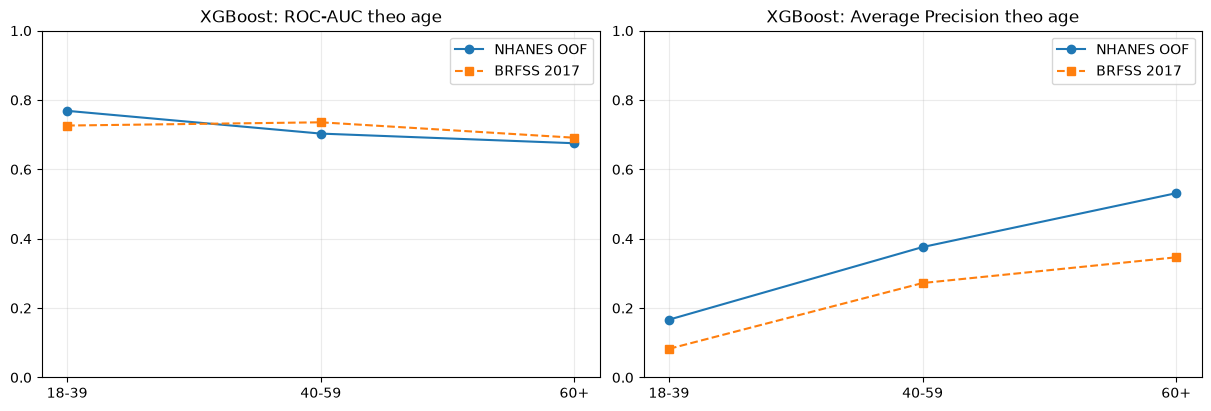

In [25]:
PLOT_MODEL = 'XGBoost'
PLOT_ATTRIBUTE = 'age'
plot_data = comparison.loc[
    comparison['model'].eq(PLOT_MODEL) & comparison['attribute'].eq(PLOT_ATTRIBUTE)
].set_index('group').reindex(primary_specs[PLOT_ATTRIBUTE])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
x = np.arange(len(plot_data))
for ax, metric, title in zip(axes, ['roc_auc', 'ap'], ['ROC-AUC', 'Average Precision']):
    ax.plot(x, plot_data[f'{metric}_internal'], 'o-', label='NHANES OOF')
    ax.plot(x, plot_data[f'{metric}_external'], 's--', label='BRFSS 2017')
    ax.set_xticks(x, plot_data.index)
    ax.set_ylim(0, 1)
    ax.set_title(f'{PLOT_MODEL}: {title} theo {PLOT_ATTRIBUTE}')
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## Bước 8 — Lưu kết quả và nguồn dữ liệu

Chỉ ghi vào `results/nhanes_to_brfss/auc_ap_dataset_shift/`; không ghi đè các kết quả fairness cũ. Manifest ghi nguồn, run ID và SHA-256 các file đã dùng để lần sau kiểm tra được kết quả đến từ đâu. Không dùng `.joblib` hiện tại trong notebook này.

Ba CSV gồm kết quả từng nhóm, so sánh nội bộ/ngoài và macro AP. Hình lưu theo lựa chọn tại Bước 7. Rerun sẽ cập nhật các file cùng tên.

In [26]:
output_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
auc_group_fig.savefig(figures_dir / 'auc_internal_external_all_groups.png', dpi=180, bbox_inches='tight')
metrics.to_csv(output_dir / 'auc_ap_by_group.csv', index=False, encoding='utf-8-sig')
comparison.to_csv(output_dir / 'internal_external_comparison.csv', index=False, encoding='utf-8-sig')
macro_ap.to_csv(output_dir / 'macro_ap_by_attribute.csv', index=False, encoding='utf-8-sig')
fig.savefig(figures_dir / f'{PLOT_MODEL}_{PLOT_ATTRIBUTE}_auc_ap.png', dpi=180, bbox_inches='tight')

manifest = {
    'internal_run': INTERNAL_RUN, 'external_final_run': EXTERNAL_RUN,
    'models': MODELS, 'internal_prediction': 'outer-fold nested CV OOF',
    'external_prediction': 'saved frozen final-model predictions on BRFSS 2017',
    'threshold_used': False, 'survey_weighted': False,
    'uncertainty': 'point estimates only; no CI or significance tests here',
    'macro_ap_definition': 'unweighted mean AP of prespecified groups within each attribute',
    'primary_groups': primary_specs,
    'comparison_scope': 'learning procedure: outer-fold models internally versus final model externally',
    'sources_sha256': {str(p.relative_to(project_dir)): hashlib.sha256(p.read_bytes()).hexdigest()
                       for p in source_paths.values()},
}
(output_dir / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu tại:', output_dir)

Đã lưu tại: d:\nckh\diabetes-ml-fairness\diabetes-project\results\auc_ap_dataset_shift


## Bước 9 — Nhận xét ROC-AUC và AP theo nhóm

### Phạm vi và nguồn kết quả

Chiều nghiên cứu: phát triển trên NHANES 2015–2018, kiểm định ngoài trên BRFSS 2017. Nội bộ là outer-fold OOF của nested CV, không phải dự đoán lại toàn bộ tập train. Nguồn: ô 9 (Bước 4), ô 13 (Bước 5), ô 15 (Bước 6), ô 11 và 17 (hình); các bảng `auc_ap_by_group.csv`, `internal_external_comparison.csv`, `macro_ap_by_attribute.csv` trong `results/nhanes_to_brfss/auc_ap_dataset_shift/`. Số ô đếm từ 1, gồm cả Markdown, không phải In[n]. Nhận xét dưới đây dùng các kết quả đã lưu, không tính lại metric.

### Hiệu năng chung và ý nghĩa của AP

| Mô hình | ROC-AUC nội bộ | ROC-AUC ngoài | AP nội bộ | AP ngoài |
|---|---:|---:|---:|---:|
| XGBoost | 0,7999 | 0,7691 | 0,4784 | 0,3218 |
| LR | 0,7950 | 0,7722 | 0,4617 | 0,3293 |

Ở nội bộ XGBoost cao hơn LR, nhưng trên BRFSS 2017 LR cao hơn ở cả hai chỉ số. Đây là so sánh ước lượng điểm; chưa có CI hoặc kiểm định trong output này. Tỷ lệ bệnh giảm từ 0,2099 xuống 0,1345 (ô 9). Như giới hạn đã ghi, AP phụ thuộc tỷ lệ bệnh nên chưa thể quy toàn bộ suy giảm AP cho bias hoặc khả năng xếp hạng. Các mô hình outer-fold và mô hình cuối cũng khác nhau; so sánh đang đánh giá quy trình học, chưa tách riêng tác động chuyển nguồn.

### Tuổi và BMI

| Tuổi | AUC XGBoost nội bộ → BRFSS | AP XGBoost nội bộ → BRFSS |
|---|---|---|
| 18-39 | 0,7688 → 0,7263 | 0,1664 → 0,0823 |
| 40-59 | 0,7032 → 0,7357 | 0,3759 → 0,2722 |
| 60+ | 0,6753 → 0,6912 | 0,5314 → 0,3464 |

Nguồn: ô 9, output 2. Người trẻ giảm cả AUC và AP. Hai nhóm tuổi còn lại tăng AUC nhưng giảm AP. LR có cùng hướng thay đổi: AUC 18-39 là 0,7653 → 0,7279; 40-59 là 0,7048 → 0,7449; 60+ là 0,6606 → 0,6953. Trong ba nhóm tuổi ngoài, 60+ có AUC thấp nhất nhưng AP cao nhất ở cả hai mô hình; 18-39 có AP thấp nhất. Tỷ lệ bệnh ngoài tương ứng 0,0231, 0,1146 và 0,2012. Không thể dùng thứ hạng AP đơn lẻ để khẳng định nhóm có khả năng phân biệt tốt hơn.

Với BMI, AUC XGBoost giảm ở cả ba nhóm chính: Normal 0,8250 → 0,7578, Overweight 0,7708 → 0,7301, Obese 0,7499 → 0,7241. LR cũng giảm ở cả ba nhóm. Delta đã lưu ở ô 13 cho thấy Normal giảm mạnh nhất trong các nhóm chính: XGBoost −0,0672, LR −0,0616. Trên BRFSS, AP XGBoost Obese 0,4146 cao hơn Normal 0,1648, trong khi AUC Obese thấp hơn; tỷ lệ bệnh lần lượt 0,2341 và 0,0612 (CSV từng nhóm). Đây là khác biệt thứ hạng cần đọc cùng tỷ lệ bệnh.

### Giới tính và chủng tộc

Trên BRFSS 2017, XGBoost có AUC/AP nam 0,7746/0,3347 và nữ 0,7680/0,3131; LR tương ứng 0,7766/0,3407 và 0,7694/0,3205. Cả hai giới đều giảm so với nội bộ; nam cao hơn nữ ở ước lượng điểm ngoài. Chưa có căn cứ từ output để xác định nguyên nhân hoặc ý nghĩa thống kê của chênh lệch này.

Theo chủng tộc, AUC ngoài cao nhất ở Hispanic (XGBoost 0,7952; LR 0,8037), thấp nhất ở Black NH (0,7515; 0,7640). Nhưng AP cao nhất lại ở Black NH (0,3854; 0,4011), thấp nhất ở White NH (0,3045; 0,3084). Tỷ lệ bệnh Black NH 0,1996 và White NH 0,1255. AUC Hispanic tăng nhẹ so với nội bộ ở cả hai mô hình, còn ba nhóm còn lại giảm. Nguồn: CSV từng nhóm và ô 13.

### mAP đúng cấp tổng hợp

Notebook gọi là `macro_ap`: trung bình cộng AP các nhóm định trước trong **từng đặc trưng**, không phải trung bình theo mô hình hoặc theo fold. Giới gồm Nam/Nữ; chủng tộc 4 nhóm; tuổi 3 nhóm; BMI chỉ Normal/Overweight/Obese. Missing và BMI Underweight không tham gia macro AP chính. Không có một mAP toàn tập chung.

Ô 15 cho thấy macro AP ngoài thấp hơn nội bộ ở cả bốn đặc trưng. Ví dụ theo tuổi: XGBoost 0,3579 → 0,2336, LR 0,3486 → 0,2410; theo BMI: 0,4032 → 0,2750 và 0,3974 → 0,2770. LR có macro AP ngoài cao hơn XGBoost ở cả bốn đặc trưng. Chỉ số tổng hợp chưa thay thế việc xem nhóm kém nhất.

### Giới hạn và hướng thử nghiệm đã được ghi nhận

Các nhóm Missing vẫn được mô tả. BMI thiếu cân NHANES chỉ có 171 người và 7 ca bệnh; Missing BMI có 228 người và 126 ca bệnh. Không nên coi các ước lượng ở nhóm ít ca bệnh là chắc chắn. Nhóm tuổi Missing có n=0 nên chỉ số không xác định, không phải bằng 0. Tỷ lệ thiếu BMI trong nhận xét gốc là 2,10% ở NHANES và 8,06% ở BRFSS; thành phần mẫu, tỷ lệ bệnh và cách ghi nhận nhãn khác nhau là các giả thuyết cần kiểm tra, chưa là nguyên nhân đã chứng minh.

Các đề xuất đã có trong phần nhận xét trước: (1) bổ sung CI cho AUC/AP và delta, giữ ghép cặp khi so mô hình; (2) kiểm tra phân bố đầu vào và mức thiếu trong từng nhóm, nhất là Normal, người trẻ, Other và Missing BMI; (3) phân tích độ nhạy về tỷ lệ bệnh và cách định nghĩa nhãn; (4) thử xử lý thiếu, biểu diễn biến, tái trọng số hoặc dữ liệu đích có nhãn khi thiết kế cho phép, rồi kiểm thử độc lập; (5) có thể đối chiếu cùng mô hình outer-fold trên hai nguồn nếu có đủ artifact. Đây đều là hướng dự kiến, chưa có kết quả khắc phục. Hiệu chỉnh đơn điệu nghiêm ngặt giữ thứ hạng nên không phải ưu tiên trực tiếp để cải thiện AUC/AP, theo giới hạn đã ghi.

Chưa áp trọng số khảo sát; CI từ điểm đã lưu cũng chưa bao phủ toàn bộ bất định training/tuning. Sau khi dùng BRFSS 2017 để chọn biện pháp, cần bảo vệ một tập kiểm thử độc lập cho cải tiến đó. Hai notebook chưa xác định nguyên nhân của chênh lệch này; chưa thể kết luận đây là bias cố hữu của BRFSS hoặc NHANES.

### Đối chiếu có điều kiện với chiều đảo ngược

Notebook 08 huấn luyện trên BRFSS 2017 và kiểm định ngoài trên NHANES, dùng cùng định nghĩa nhóm và hàm ROC-AUC/AP. Ở NHANES ngoài, AUC/AP XGBoost là 0,797822/0,472544, LR 0,789867/0,453029 (08, ô 28). Có thể đặt cạnh NHANES OOF ở bảng đầu để mô tả, nhưng hai chế độ đánh giá và nguồn huấn luyện khác nhau nên không gọi đó là mức cải thiện do đảo chiều. AUC thấp nhất theo tuổi vẫn là nhóm ≥60 và AP thấp nhất là 18–39. Notebook 08 chưa có macro AP hoặc AUC/AP nội bộ theo nhóm tương đương để so mức suy giảm hai chiều.

**Đối chiếu nguồn:** ô 5, output 1 còn hiển thị đường dẫn `results/tuning/…` và `results/external_validation/…`, trong khi code đã dùng tiền tố `results/nhanes_to_brfss/…`. Đây là lệch đường dẫn hiển thị, chưa chứng minh số liệu sai. Nguồn số được ưu tiên là output đã lưu và CSV được tham chiếu; code/output không được chạy lại trong lần cập nhật nhận xét này.


## Bước 10 — Phân tích bổ sung về bất định và chuyển dịch dữ liệu

**Có thể bắt đầu chạy từ cell ngay dưới đây sau Restart Kernel, không cần chạy lại các bước trước và không huấn luyện lại.** Phần này nạp dự đoán đã lưu của đúng chiều 07. Các bảng/nhận xét trước mục này vẫn mô tả phân tích gốc; CI và phân tích độ nhạy được lưu riêng trong `research_checks/<analysis_id>`.

Phương pháp dùng chung ở `src/dataset_shift.py` cho cả hai notebook. Ba mục tiêu là lượng hóa độ bất định, mô tả phân bố/mức thiếu của tám đầu vào và kiểm tra độ nhạy với tỷ lệ bệnh hoặc định nghĩa nhãn. Không dùng ngưỡng dự đoán, không đổi mô hình, không chọn cấu hình bằng kết quả kiểm định.

**Cấu hình trước khi chạy:** 1.000 lần bootstrap, CI 95%, seed 42. Có thể tăng `SHIFT_N_BOOT` cho bản báo cáo cuối; thay cấu hình tạo thư mục kết quả mới. Tỷ lệ bệnh tham chiếu chính là 15% cho cả hai notebook và mọi nhóm; kiểm tra thêm 10% và 20% để thể hiện độ nhạy với lựa chọn tham chiếu. Đây là các kịch bản phân tích, không phải tỷ lệ bệnh ước lượng của một quần thể đích.

In [1]:
from pathlib import Path
import hashlib
import importlib
import importlib.metadata
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

shift_project = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / 'src/utils.py').is_file() and (p / 'data/processed').is_dir())
if str(shift_project) not in sys.path:
    sys.path.insert(0, str(shift_project))
from src import dataset_shift as shift_tools
shift_tools = importlib.reload(shift_tools)

SHIFT_N_BOOT = 1000
SHIFT_CONFIDENCE = 0.95
SHIFT_SEED = 42
SHIFT_REFERENCE_PREVALENCE = 0.15
SHIFT_PREVALENCE_GRID = [0.10, 0.15, 0.20]
SHIFT_REVERSE_RUN = '79dce7d27030baa2'
SHIFT_PRIORITIES = [('age', '18-39'), ('bmi', 'Normal'), ('bmi', 'Underweight'), ('bmi', 'Missing'), ('race_ethnicity', 'Other')]
shift_bundle = shift_tools.load_saved_analysis(shift_project, '07', SHIFT_REVERSE_RUN)
shift_sources = dict(shift_bundle['paths'])
shift_sources['analysis_code'] = shift_project / 'src/dataset_shift.py'
for shift_cycle, shift_suffix in [('2015-2016', 'I'), ('2017-2018', 'J')]:
    shift_path = shift_project / f'data/raw/nhanes/{shift_cycle}/DIQ_{shift_suffix}.xpt'
    if shift_path.exists():
        shift_sources['self_report_' + shift_cycle] = shift_path
shift_source_hashes = {str(p.relative_to(shift_project)): shift_tools.file_hash(p) for p in shift_sources.values()}
shift_notebook_path = shift_project / 'notebooks/07_auc_ap_dataset_shift.ipynb'
shift_notebook = json.loads(shift_notebook_path.read_text(encoding='utf-8'))
shift_extension_source = '\n'.join(''.join(c['source']) for c in shift_notebook['cells']
                                   if c['cell_type'] == 'code' and c.get('metadata', {}).get('analysis_extension'))
shift_config = {
    'direction': '07', 'internal': shift_bundle['internal'], 'external': shift_bundle['external'],
    'n_boot': SHIFT_N_BOOT, 'confidence': SHIFT_CONFIDENCE, 'seed': SHIFT_SEED,
    'method': 'ordinary IID person bootstrap; percentile; fixed predictions; paired model comparisons',
    'prevalence_reference': SHIFT_REFERENCE_PREVALENCE, 'prevalence_grid': SHIFT_PREVALENCE_GRID,
    'priorities': SHIFT_PRIORITIES, 'sources_sha256': shift_source_hashes,
    'extension_code_sha256': hashlib.sha256(shift_extension_source.encode()).hexdigest(),
    'versions': {name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'scipy']},
}
shift_id = hashlib.sha256(json.dumps(shift_config, sort_keys=True).encode()).hexdigest()[:16]
shift_base = (shift_project / 'results/nhanes_to_brfss/auc_ap_dataset_shift' if '07' == '07'
              else shift_project / 'results/brfss_to_nhanes/holdout_validation' / SHIFT_REVERSE_RUN)
shift_dir = shift_base / 'research_checks' / shift_id
shift_figures_dir = shift_dir / 'figures'
shift_figures_dir.mkdir(parents=True, exist_ok=True)
(shift_dir / 'config.json').write_text(json.dumps(shift_config, ensure_ascii=False, indent=2), encoding='utf-8')
shift_tables = {}
print('Phân tích:', shift_id, '\nKết quả:', shift_dir)
display(pd.DataFrame([{'dataset': d, 'n': len(f), 'n_positive': int(f['y_true'].sum()),
                       'positive_rate': f['y_true'].mean()} for d, f in shift_bundle['cohorts'].items()]).round(4))

Phân tích: 763a58f67aff09cb 
Kết quả: D:\nckh\diabetes-ml-fairness\diabetes-project\results\nhanes_to_brfss\auc_ap_dataset_shift\research_checks\763a58f67aff09cb


,dataset,n,n_positive,positive_rate
0,NHANES_OOF,10832,2274,0.2099
1,BRFSS_2017,449219,60440,0.1345


## Bước 11 — CI 95% cho ROC-AUC, AP và chênh lệch

Bootstrap lấy mẫu người có hoàn lại trong từng tập/nhóm, giữ nguyên cỡ mẫu và điểm dự đoán. LR và XGBoost dùng **cùng người lấy mẫu ở mỗi lần** để tính CI của `XGBoost − LR`. Hai quần thể nội bộ/ngoài được lấy mẫu độc lập để tính CI của `ngoài − nội bộ`. Báo cả n, số dương, số âm, số lần bootstrap hợp lệ; lần chỉ có một lớp giữ NA. Chỉ xuất CI khi ít nhất 90% lần bootstrap hợp lệ.

Đây là **CI percentile theo từng phép đối chiếu**, chưa hiệu chỉnh đa so sánh. CI không chứa 0 chỉ là dấu hiệu chênh lệch dưới giả định bootstrap đang dùng, không xác định nguyên nhân hoặc thiên kiến. CI phản ánh bất định trên mẫu đánh giá với điểm dự đoán cố định; không bao gồm bất định từ chọn tham số/huấn luyện lại. Với 07, các điểm OOF đến từ mô hình dùng chung dữ liệu huấn luyện nên CI này chỉ là xấp xỉ mô tả, không phải suy luận đầy đủ cho nested CV. Cả hai notebook chưa dùng bootstrap theo cụm/strata/trọng số khảo sát; kết quả không phải CI đại diện dân số theo thiết kế NHANES/BRFSS.

Tính cho tất cả nhóm, ưu tiên xem Underweight, 18-39 và các nhóm ghi nhận giảm AUC. Cache lưu các mẫu bootstrap theo dữ liệu và cấu hình, có thể chạy tiếp cell này khi gián đoạn.

In [2]:
shift_ci = shift_tools.uncertainty_tables(
    shift_bundle, shift_dir, n_boot=SHIFT_N_BOOT, confidence=SHIFT_CONFIDENCE, seed=SHIFT_SEED,
)
shift_tables.update(shift_ci)
for shift_name, shift_table in shift_ci.items():
    shift_table.to_csv(shift_dir / f'{shift_name}.csv', index=False, na_rep='NA')
shift_focus = lambda table: table['attribute'].eq('overall') | pd.Series(
    [(a, g) in SHIFT_PRIORITIES for a, g in zip(table['attribute'], table['group'])], index=table.index)
print('CI từng tập/nhóm; xem file metric_ci.csv cho đầy đủ')
display(shift_ci['metric_ci'].loc[shift_focus(shift_ci['metric_ci'])].round(4))
print('Ngoài − nội bộ; CI ở thang 0–1')
display(shift_ci['external_internal_delta_ci'].loc[shift_focus(shift_ci['external_internal_delta_ci'])].round(4))
print('XGBoost − LR trên cùng người kiểm định')
display(shift_ci['paired_model_delta_ci'].query("attribute == 'overall'").round(4))

CI overall/All: done (1000 replicates, cached)


CI sex/Nam: done (1000 replicates, cached)


CI sex/Nữ: done (1000 replicates, cached)


CI sex/Missing: done (1000 replicates, cached)


CI race_ethnicity/White NH: done (1000 replicates, cached)


CI race_ethnicity/Black NH: done (1000 replicates, cached)


... (14 outputs left out)

Ngoài − nội bộ; CI ở thang 0–1


,model,attribute,group,metric,internal,external,n_internal,n_positive_internal,n_negative_internal,n_external,n_positive_external,n_negative_external,estimate,ci_low,ci_high,n_boot_valid,n_boot,confidence,status
0,LR,overall,All,auc_roc,NHANES_OOF,BRFSS_2017,10832,2274,8558,449219,60440,388779,-0.0228,-0.0320,-0.0135,1000,1000,0.95,ok
1,LR,overall,All,ap,NHANES_OOF,BRFSS_2017,10832,2274,8558,449219,60440,388779,-0.1325,-0.1544,-0.1115,1000,1000,0.95,ok
2,XGBoost,overall,All,auc_roc,NHANES_OOF,BRFSS_2017,10832,2274,8558,449219,60440,388779,-0.0308,-0.0400,-0.0216,1000,1000,0.95,ok
3,XGBoost,overall,All,ap,NHANES_OOF,BRFSS_2017,10832,2274,8558,449219,60440,388779,-0.1566,-0.1784,-0.1356,1000,1000,0.95,ok
28,LR,race_ethnicity,Other,auc_roc,NHANES_OOF,BRFSS_2017,1879,373,1506,31148,4684,26464,-0.0425,-0.0647,-0.0202,1000,1000,0.95,ok
29,LR,race_ethnicity,Other,ap,NHANES_OOF,BRFSS_2017,1879,373,1506,31148,4684,26464,-0.1325,-0.1938,-0.0843,1000,1000,0.95,ok
30,XGBoost,race_ethnicity,Other,auc_roc,NHANES_OOF,BRFSS_2017,1879,373,1506,31148,4684,26464,-0.0485,-0.0705,-0.0265,1000,1000,0.95,ok
31,XGBoost,race_ethnicity,Other,ap,NHANES_OOF,BRFSS_2017,1879,373,1506,31148,4684,26464,-0.1544,-0.2139,-0.1056,1000,1000,0.95,ok
36,LR,age,18-39,auc_roc,NHANES_OOF,BRFSS_2017,3720,170,3550,99769,2300,97469,-0.0374,-0.0747,0.0005,1000,1000,0.95,ok
37,LR,age,18-39,ap,NHANES_OOF,BRFSS_2017,3720,170,3550,99769,2300,97469,-0.0751,-0.1296,-0.0365,1000,1000,0.95,ok


XGBoost − LR trên cùng người kiểm định


,dataset,attribute,group,n,n_positive,n_negative,metric,contrast,estimate,ci_low,ci_high,n_boot_valid,n_boot,confidence,status
0,NHANES_OOF,overall,All,10832,2274,8558,auc_roc,XGBoost - LR,0.0048,0.0012,0.0080,1000,1000,0.95,ok
1,NHANES_OOF,overall,All,10832,2274,8558,ap,XGBoost - LR,0.0167,0.0059,0.0271,1000,1000,0.95,ok
2,BRFSS_2017,overall,All,449219,60440,388779,auc_roc,XGBoost - LR,-0.0032,-0.0042,-0.0020,1000,1000,0.95,ok
3,BRFSS_2017,overall,All,449219,60440,388779,ap,XGBoost - LR,-0.0074,-0.0095,-0.0054,1000,1000,0.95,ok


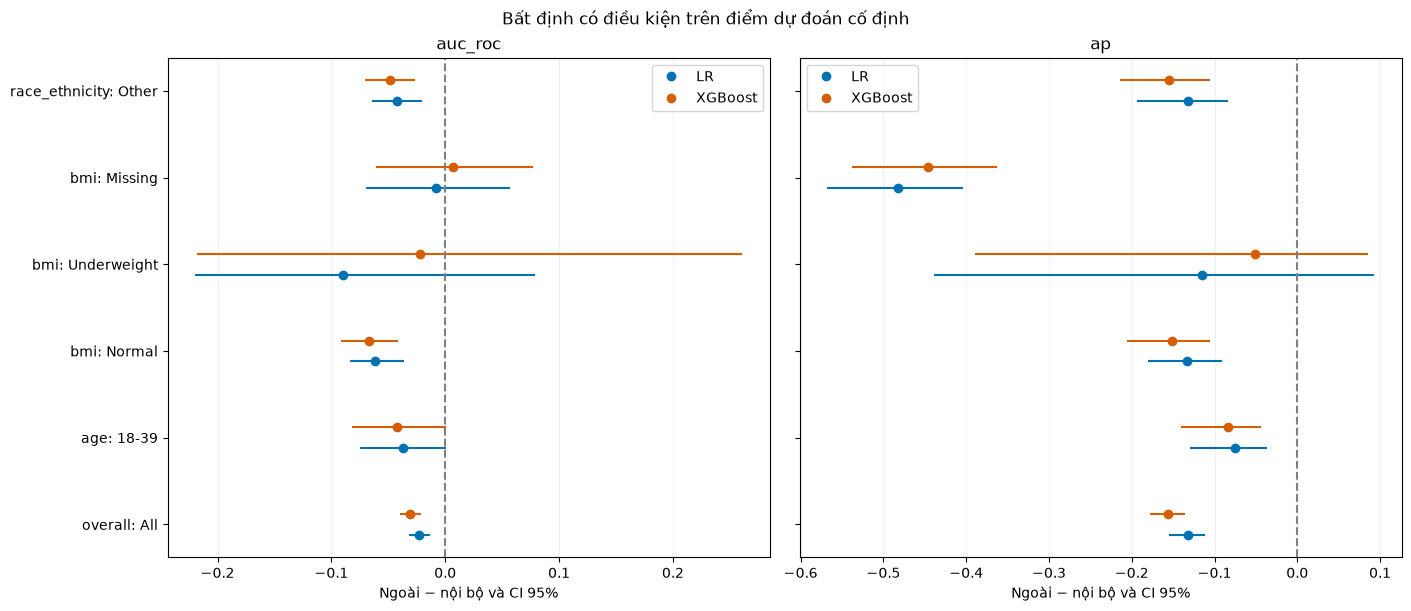

In [3]:
shift_delta = shift_ci['external_internal_delta_ci']
shift_plot_groups = [('overall', 'All')] + SHIFT_PRIORITIES
shift_fig, shift_axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True, constrained_layout=True)
for shift_ax, shift_metric in zip(shift_axes, ['auc_roc', 'ap']):
    for shift_offset, shift_model, shift_color in [(-.12, 'LR', '#0072B2'), (.12, 'XGBoost', '#D55E00')]:
        for shift_i, (shift_attribute, shift_group) in enumerate(shift_plot_groups):
            shift_row = shift_delta.loc[shift_delta['model'].eq(shift_model) & shift_delta['metric'].eq(shift_metric)
                                        & shift_delta['attribute'].eq(shift_attribute) & shift_delta['group'].eq(shift_group)].iloc[0]
            shift_y = shift_i + shift_offset
            if np.isfinite(shift_row['ci_low']) and np.isfinite(shift_row['ci_high']):
                shift_ax.hlines(shift_y, shift_row['ci_low'], shift_row['ci_high'], color=shift_color)
                shift_ax.plot(shift_row['estimate'], shift_y, 'o', color=shift_color,
                              label=shift_model if shift_i == 0 else None)
    shift_ax.axvline(0, linestyle='--', color='gray')
    shift_ax.set(yticks=np.arange(len(shift_plot_groups)),
                 yticklabels=[f'{a}: {g}' for a, g in shift_plot_groups],
                 xlabel='Ngoài − nội bộ và CI 95%', title=shift_metric)
    shift_ax.legend()
    shift_ax.grid(axis='x', alpha=.2)
shift_fig.suptitle('Bất định có điều kiện trên điểm dự đoán cố định')
shift_fig.savefig(shift_figures_dir / 'delta_ci_priority_groups.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(shift_fig)

## Bước 12 — Phân bố tám đầu vào và dữ liệu thiếu

So sánh toàn tập và từng nhóm trên đúng các quần thể kiểm định, không dùng mẫu tuning thay tập test. Tuổi/BMI: n quan sát, trung bình, SD, các phân vị, chênh trung bình chuẩn hóa, KS và khoảng cách Wasserstein. SMD = (trung bình ngoài − nội bộ)/√[(SD² nội bộ + SD² ngoài)/2]; Wasserstein ở đơn vị gốc (năm, kg/m²). Biến phân loại: tần suất/tỷ lệ từng mức và total variation = ½ tổng chênh tuyệt đối tỷ lệ. Missing được tính như một mức riêng cho biến phân loại; với số liên tục, khoảng cách chỉ dùng quan sát không thiếu và báo mức thiếu riêng.

Các số này mang tính mô tả, không áp ngưỡng tự động để kết luận bias hoặc nguyên nhân. Chỉ số của biến dùng để định nghĩa nhóm cũng được giữ để kiểm tra, nhưng phân bố trong nhóm bị giới hạn bởi chính ranh giới nhóm. Ví dụ, BMI trong nhóm Missing không có giá trị quan sát, nên khoảng cách giữ NA.

,dataset,attribute,group,n,fraction_of_cohort,n_positive,positive_rate
0,NHANES_OOF,overall,All,10832,1.0000,2274,0.209934
1,BRFSS_2017,overall,All,449219,1.0000,60440,0.134545
14,NHANES_OOF,race_ethnicity,Other,1879,0.1735,373,0.19851
15,BRFSS_2017,race_ethnicity,Other,31148,0.0693,4684,0.150379
18,NHANES_OOF,age,18-39,3720,0.3434,170,0.045699
19,BRFSS_2017,age,18-39,99769,0.2221,2300,0.023053
26,NHANES_OOF,bmi,Underweight,171,0.0158,7,0.040936
27,BRFSS_2017,bmi,Underweight,6907,0.0154,339,0.049081
28,NHANES_OOF,bmi,Normal,2737,0.2527,271,0.099014
29,BRFSS_2017,bmi,Normal,128710,0.2865,7878,0.061207


,attribute,group,feature,n_internal,n_external,delta_missing_rate,kind,ks_statistic,wasserstein,standardized_mean_difference,total_variation,status
0,overall,All,age,10832,449219,0.0000,numeric,0.1453,5.7161,0.3188,NaN,ok
1,overall,All,sex,10832,449219,0.0006,categorical,NaN,NaN,NaN,0.0406,ok
2,overall,All,race_ethnicity,10832,449219,0.0193,categorical,NaN,NaN,NaN,0.4335,ok
3,overall,All,bmi,10832,449219,0.0596,numeric,0.1055,1.4372,-0.2115,NaN,ok
4,overall,All,smoking_status,10832,449219,0.0406,categorical,NaN,NaN,NaN,0.0831,ok
5,overall,All,physical_activity,10832,449219,0.1088,categorical,NaN,NaN,NaN,0.2268,ok
6,overall,All,heart_attack,10832,449219,-0.0411,categorical,NaN,NaN,NaN,0.0411,ok
7,overall,All,stroke,10832,449219,-0.0430,categorical,NaN,NaN,NaN,0.0430,ok
56,race_ethnicity,Other,age,1879,31148,0.0000,numeric,0.0756,2.4436,0.1406,NaN,ok
57,race_ethnicity,Other,sex,1879,31148,0.0009,categorical,NaN,NaN,NaN,0.0151,ok


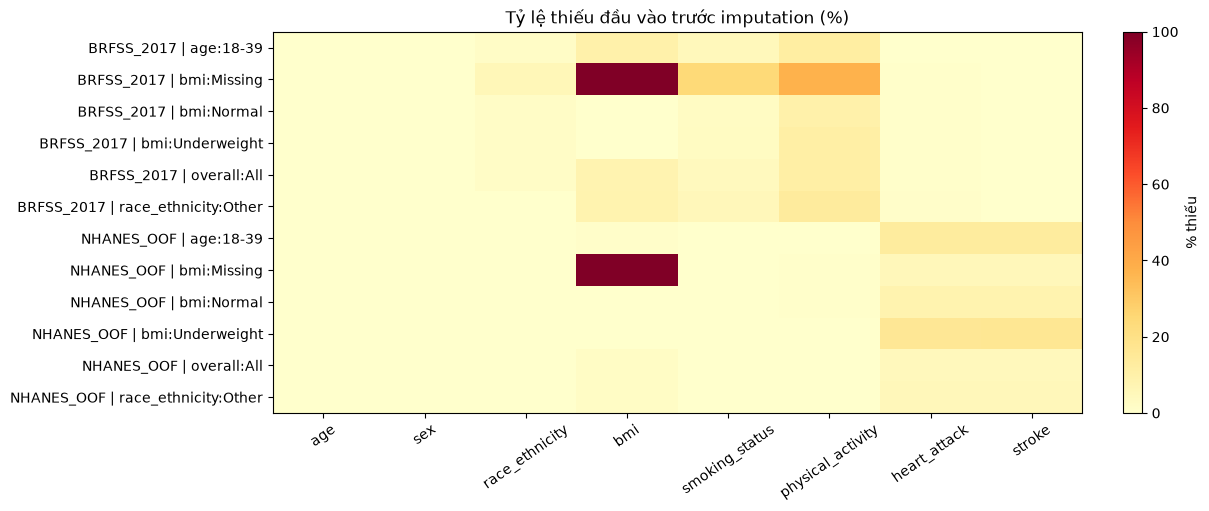

In [4]:
shift_distribution = shift_tools.distribution_tables(shift_bundle)
shift_tables.update(shift_distribution)
for shift_name, shift_table in shift_distribution.items():
    shift_table.to_csv(shift_dir / f'{shift_name}.csv', index=False, na_rep='NA')
display(shift_distribution['group_composition'].loc[shift_focus(shift_distribution['group_composition'])].round(4))
display(shift_distribution['input_shift'].loc[shift_focus(shift_distribution['input_shift'])].round(4))
shift_missing = shift_distribution['missingness'].loc[shift_focus(shift_distribution['missingness'])].copy()
shift_missing['cohort_group'] = shift_missing['dataset'] + ' | ' + shift_missing['attribute'] + ':' + shift_missing['group']
shift_heat = shift_missing.pivot(index='cohort_group', columns='feature', values='missing_rate').reindex(columns=shift_tools.FEATURES)
shift_fig, shift_ax = plt.subplots(figsize=(12, max(5, len(shift_heat)*.35)), constrained_layout=True)
shift_image = shift_ax.imshow(np.ma.masked_invalid(shift_heat.to_numpy(float)*100), vmin=0, vmax=100, aspect='auto', cmap='YlOrRd')
shift_ax.set(xticks=np.arange(len(shift_heat.columns)), xticklabels=shift_heat.columns,
             yticks=np.arange(len(shift_heat)), yticklabels=shift_heat.index,
             title='Tỷ lệ thiếu đầu vào trước imputation (%)')
shift_ax.tick_params(axis='x', rotation=35)
shift_fig.colorbar(shift_image, ax=shift_ax, label='% thiếu')
shift_fig.savefig(shift_figures_dir / 'missingness_priority_groups.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(shift_fig)

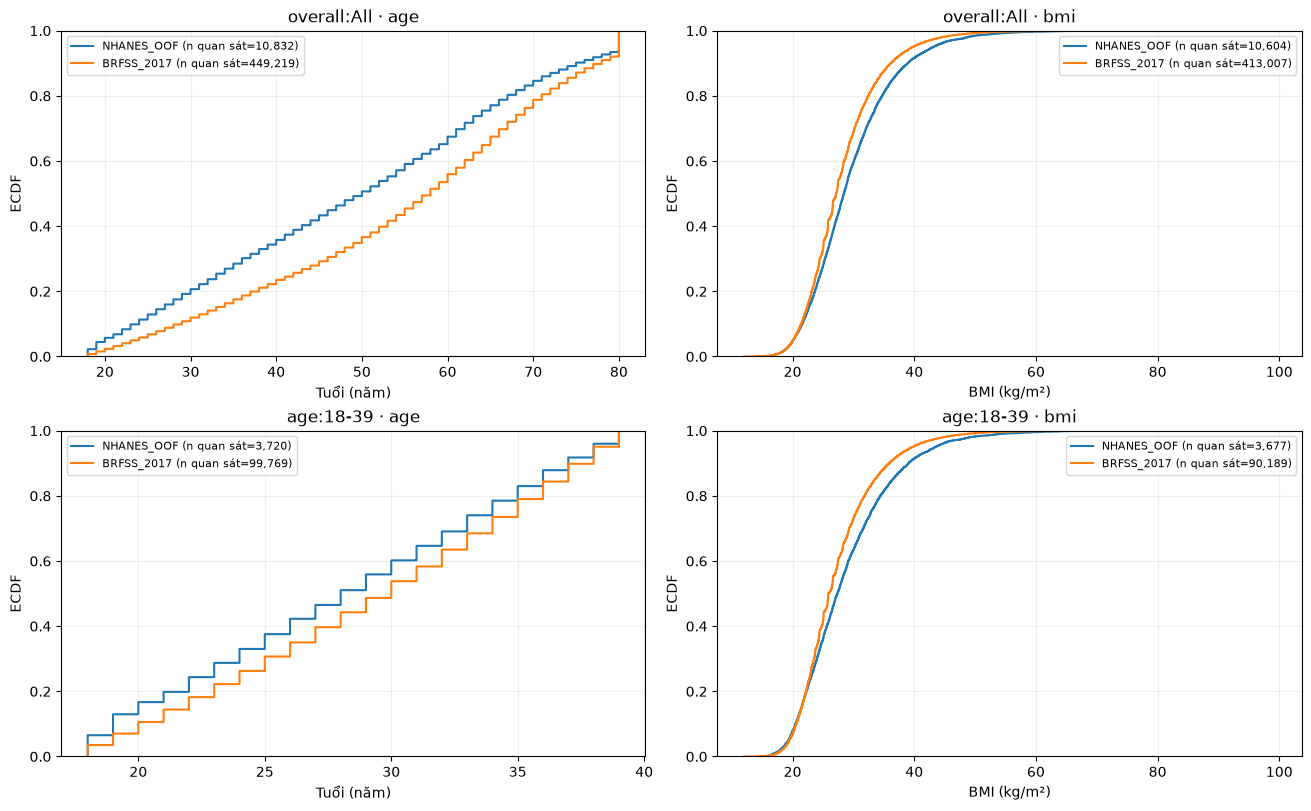

In [5]:
# ECDF toàn tập và trong một nhóm ưu tiên; đổi lựa chọn để xem nhóm khác.
SHIFT_DISTRIBUTION_GROUP = SHIFT_PRIORITIES[0]
shift_fig, shift_axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for shift_row, (shift_attribute, shift_group) in enumerate([('overall', 'All'), SHIFT_DISTRIBUTION_GROUP]):
    for shift_col, shift_feature in enumerate(['age', 'bmi']):
        shift_ax = shift_axes[shift_row, shift_col]
        for shift_dataset, shift_frame in shift_bundle['cohorts'].items():
            shift_mask = next(m for a, g, m in shift_tools.masks(shift_frame) if a == shift_attribute and g == shift_group)
            shift_values = np.sort(shift_frame.loc[shift_mask, shift_feature].dropna().to_numpy(dtype=float))
            if len(shift_values):
                shift_ax.step(shift_values, np.arange(1, len(shift_values)+1)/len(shift_values), where='post',
                              label=f'{shift_dataset} (n quan sát={len(shift_values):,})')
        shift_ax.set(title=f'{shift_attribute}:{shift_group} · {shift_feature}',
                     xlabel='Tuổi (năm)' if shift_feature == 'age' else 'BMI (kg/m²)', ylabel='ECDF', ylim=(0,1))
        shift_ax.legend(fontsize=8)
        shift_ax.grid(alpha=.2)
shift_fig.savefig(shift_figures_dir / 'numeric_ecdf.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(shift_fig)

## Bước 13 — Độ nhạy AP với tỷ lệ bệnh tham chiếu chung

Trong mỗi tập/nhóm, gán trọng số lớp dương `p_ref/n_positive`, lớp âm `(1−p_ref)/n_negative`, rồi gọi `average_precision_score(..., sample_weight=...)`. Như vậy mọi nhóm được đưa về cùng tỷ lệ dương tham chiếu; giữ nguyên điểm và thứ hạng, không lấy AP chia tỷ lệ bệnh. AUC không đổi dưới phép nhân trọng số hằng trong từng lớp này. mAP chuẩn hóa vẫn trung bình AP chuẩn hóa của các nhóm chính trong từng đặc trưng.

Đây chỉ là phân tích độ nhạy với tỷ lệ lớp, không sửa được khác biệt phân bố đặc trưng, chất lượng nhãn hoặc sai lệch đo lường. Không diễn giải AP chuẩn hóa là hiệu năng đã quan sát trên một quần thể mới. Nhóm thiếu một lớp giữ NA.

,dataset,model,attribute,group,n,n_positive,n_negative,observed_prevalence,reference_prevalence,ap_observed,ap_standardized,auc_roc,status
72,NHANES_OOF,LR,overall,All,10832,2274,8558,0.2099,0.15,0.4617,0.3660,0.7950,ok
79,NHANES_OOF,LR,race_ethnicity,Other,1879,373,1506,0.1985,0.15,0.4927,0.4123,0.8259,ok
81,NHANES_OOF,LR,age,18-39,3720,170,3550,0.0457,0.15,0.1578,0.3859,0.7653,ok
85,NHANES_OOF,LR,bmi,Underweight,171,7,164,0.0409,0.15,0.2525,0.4629,0.8092,ok
86,NHANES_OOF,LR,bmi,Normal,2737,271,2466,0.0990,0.15,0.3035,0.4079,0.8267,ok
89,NHANES_OOF,LR,bmi,Missing,228,126,102,0.5526,0.15,0.7199,0.2779,0.7245,ok
90,BRFSS_2017,LR,overall,All,449219,60440,388779,0.1345,0.15,0.3293,0.3565,0.7722,ok
97,BRFSS_2017,LR,race_ethnicity,Other,31148,4684,26464,0.1504,0.15,0.3602,0.3596,0.7834,ok
99,BRFSS_2017,LR,age,18-39,99769,2300,97469,0.0231,0.15,0.0826,0.3677,0.7279,ok
103,BRFSS_2017,LR,bmi,Underweight,6907,339,6568,0.0491,0.15,0.1372,0.3298,0.7193,ok


,dataset,model,attribute,reference_prevalence,n_groups,n_groups_valid,map_observed,map_standardized
16,NHANES_OOF,LR,sex,0.15,2,2,0.4610,0.3651
17,NHANES_OOF,LR,race_ethnicity,0.15,4,4,0.4669,0.3707
18,NHANES_OOF,LR,age,0.15,3,3,0.3486,0.3071
19,NHANES_OOF,LR,bmi,0.15,3,3,0.3974,0.3500
20,BRFSS_2017,LR,sex,0.15,2,2,0.3306,0.3572
21,BRFSS_2017,LR,race_ethnicity,0.15,4,4,0.3597,0.3552
22,BRFSS_2017,LR,age,0.15,3,3,0.2410,0.3322
23,BRFSS_2017,LR,bmi,0.15,3,3,0.2770,0.3137
24,NHANES_OOF,XGBoost,sex,0.15,2,2,0.4766,0.3809
25,NHANES_OOF,XGBoost,race_ethnicity,0.15,4,4,0.4822,0.3860


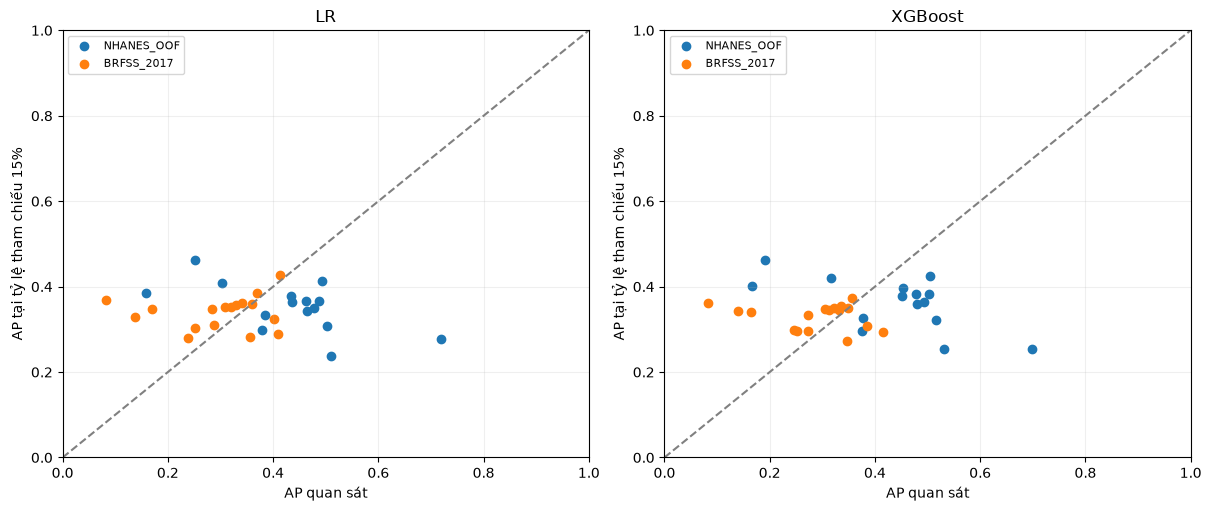

In [6]:
shift_sensitivity_parts, shift_macro_parts = [], []
for shift_prevalence in sorted(set(SHIFT_PREVALENCE_GRID + [SHIFT_REFERENCE_PREVALENCE])):
    shift_part = shift_tools.prevalence_sensitivity(shift_bundle, shift_prevalence)
    shift_sensitivity_parts.append(shift_part['prevalence_sensitivity'])
    shift_macro_parts.append(shift_part['prevalence_macro_ap'])
shift_tables['prevalence_sensitivity'] = pd.concat(shift_sensitivity_parts, ignore_index=True)
shift_tables['prevalence_macro_ap'] = pd.concat(shift_macro_parts, ignore_index=True)
for shift_name in ['prevalence_sensitivity', 'prevalence_macro_ap']:
    shift_tables[shift_name].to_csv(shift_dir / f'{shift_name}.csv', index=False, na_rep='NA')
shift_prevalence_main = shift_tables['prevalence_sensitivity'].loc[
    np.isclose(shift_tables['prevalence_sensitivity']['reference_prevalence'], SHIFT_REFERENCE_PREVALENCE)]
display(shift_prevalence_main.loc[shift_focus(shift_prevalence_main)].round(4))
display(shift_tables['prevalence_macro_ap'].loc[
    np.isclose(shift_tables['prevalence_macro_ap']['reference_prevalence'], SHIFT_REFERENCE_PREVALENCE)].round(4))
shift_fig, shift_axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for shift_ax, shift_model in zip(shift_axes, shift_tools.MODELS):
    for shift_dataset in shift_bundle['cohorts']:
        shift_part = shift_prevalence_main.loc[shift_prevalence_main['model'].eq(shift_model)
                                              & shift_prevalence_main['dataset'].eq(shift_dataset)]
        shift_ax.scatter(shift_part['ap_observed'], shift_part['ap_standardized'], label=shift_dataset)
    shift_ax.plot([0,1], [0,1], '--', color='gray')
    shift_ax.set(title=shift_model, xlabel='AP quan sát', ylabel=f'AP tại tỷ lệ tham chiếu {SHIFT_REFERENCE_PREVALENCE:.0%}',
                 xlim=(0,1), ylim=(0,1))
    shift_ax.legend(fontsize=8)
    shift_ax.grid(alpha=.2)
shift_fig.savefig(shift_figures_dir / 'ap_prevalence_sensitivity.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(shift_fig)

## Bước 14 — Độ nhạy với nhãn chẩn đoán tự khai

Dữ liệu processed NHANES không giữ `DIQ010`; nối từ `data/raw/nhanes/2015-2016/DIQ_I.xpt` và `2017-2018/DIQ_J.xpt` bằng `SEQN × cycle`. Quy ước nhãn thay thế: `DIQ010=1` dương, `2/3` (không bệnh/borderline) âm, còn lại hoặc thiếu loại khỏi phân tích. BRFSS giữ nhãn đã dùng ở notebook 01 (`DIABETE3=1` dương, `2/3/4` âm).

Hai nguồn cùng gần khái niệm chẩn đoán tự khai hơn, **chưa được khẳng định tương đương hoàn toàn**. Đây là đánh giá lại ROC-AUC/AP của **điểm dự đoán cố định** với một định nghĩa đầu ra khác; không phải mô hình đã huấn luyện bằng nhãn mới, cũng không phải một quy trình dự báo mới được kiểm định độc lập. So sánh nhãn gốc và nhãn thay thế trên cùng tập người có câu trả lời hợp lệ; báo số bị loại và bảng chuyển nhãn để tránh nhầm ảnh hưởng của loại mẫu với đổi nhãn. Nếu thiếu file gốc, xuất trạng thái chưa đủ nguồn thay vì suy diễn nhãn.

In [7]:
shift_label_tables, shift_label_paths = shift_tools.self_report_sensitivity(shift_bundle, shift_project)
shift_tables.update(shift_label_tables)
for shift_name, shift_table in shift_label_tables.items():
    shift_table.to_csv(shift_dir / f'{shift_name}.csv', index=False, na_rep='NA')
if 'label_sensitivity_status' in shift_label_tables:
    display(shift_label_tables['label_sensitivity_status'])
else:
    display(shift_label_tables['label_coverage'])
    display(shift_label_tables['label_transition'])
    shift_label_results = shift_label_tables['label_sensitivity']
    display(shift_label_results.loc[shift_focus(shift_label_results)].round(4))

,dataset,n_original,n_included,n_excluded_unknown_self_report,n_label_changed
0,NHANES_OOF,10832,10830,2,549
1,BRFSS_2017,449219,449219,0,0


,dataset,original_y,alternative_y,n
0,NHANES_OOF,0,0,8558
1,NHANES_OOF,1,0,549
2,NHANES_OOF,1,1,1723
3,NHANES_OOF,1,Excluded,2
4,BRFSS_2017,0,0,388779
5,BRFSS_2017,1,1,60440


,dataset,endpoint,model,attribute,group,n,n_positive,n_negative,positive_rate,auc_roc,ap,status
0,NHANES_OOF,original_on_common_subset,LR,overall,All,10830,2272,8558,0.2098,0.7949,0.4614,ok
7,NHANES_OOF,original_on_common_subset,LR,race_ethnicity,Other,1879,373,1506,0.1985,0.8259,0.4927,ok
9,NHANES_OOF,original_on_common_subset,LR,age,18-39,3720,170,3550,0.0457,0.7653,0.1578,ok
13,NHANES_OOF,original_on_common_subset,LR,bmi,Underweight,171,7,164,0.0409,0.8092,0.2525,ok
14,NHANES_OOF,original_on_common_subset,LR,bmi,Normal,2737,271,2466,0.0990,0.8267,0.3035,ok
17,NHANES_OOF,original_on_common_subset,LR,bmi,Missing,228,126,102,0.5526,0.7245,0.7199,ok
18,NHANES_OOF,self_report,LR,overall,All,10830,1723,9107,0.1591,0.7938,0.3839,ok
25,NHANES_OOF,self_report,LR,race_ethnicity,Other,1879,270,1609,0.1437,0.8255,0.3983,ok
27,NHANES_OOF,self_report,LR,age,18-39,3720,102,3618,0.0274,0.7225,0.0844,ok
31,NHANES_OOF,self_report,LR,bmi,Underweight,171,5,166,0.0292,0.7506,0.0742,ok


## Bước 15 — Lưu nguồn và cách kết luận phần bổ sung

Đọc kết quả theo thứ tự: (1) ước lượng và CI của AUC/AP, đặc biệt nhóm ít ca bệnh; (2) CI của chênh lệch ngoài − nội bộ; (3) phân bố đầu vào và thiếu dữ liệu trong các nhóm đó; (4) AP khi cùng tỷ lệ tham chiếu; (5) kết quả với nhãn tự khai trên cùng tập người. Không dùng việc hai CI riêng lẻ chồng lấp hay không để thay cho CI chênh lệch.

Mức thiếu hoặc phân bố khác nhau là bằng chứng mô tả về chuyển dịch đầu vào, chưa chứng minh đó là nguyên nhân làm AUC giảm. Nếu chênh AP thay đổi khi chuẩn hóa tỷ lệ bệnh, chỉ kết luận kết quả AP nhạy với kịch bản tỷ lệ bệnh. Nếu đổi nhãn làm metric thay đổi, chỉ kết luận nhạy với định nghĩa đầu ra trên điểm dự đoán đã lưu. Chưa có biện pháp khắc phục nào được huấn luyện/thử trong phần bổ sung.

**Tài liệu phương pháp:** [scikit-learn average_precision_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html) mô tả AP và `sample_weight`; [SciPy bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html) mô tả lấy mẫu có hoàn lại, percentile CI và lấy mẫu ghép cặp. Tính percentile được triển khai với thứ tự điểm có ties giữ nguyên để giảm chi phí; các phép tính đã được đối chiếu bằng kiểm thử với scikit-learn. Định nghĩa nhãn thay thế là quy ước độ nhạy đã nêu rõ, không lấy từ hai trang tài liệu metric.

In [8]:
for shift_filename, shift_digest in shift_source_hashes.items():
    assert shift_tools.file_hash(shift_project / shift_filename) == shift_digest, shift_filename
shift_manifest = {
    'analysis_id': shift_id, 'config': shift_config,
    'frozen_scores': True, 'models_refitted': False, 'threshold_used': False,
    'ci_scope': 'fixed-score IID person-level approximation; not retraining or survey-design uncertainty',
    'label_scope': 'frozen-score endpoint sensitivity, original and alternative labels on common subset',
    'output_sha256': {str(p.relative_to(shift_dir)): shift_tools.file_hash(p)
                      for p in shift_dir.rglob('*') if p.is_file() and p.name != 'manifest.json'},
}
(shift_dir / 'manifest.json').write_text(json.dumps(shift_manifest, ensure_ascii=False, indent=2), encoding='utf-8')
print('Hoàn tất phân tích bổ sung:', shift_dir)
display(pd.DataFrame([{'table': name, 'rows': len(table)} for name, table in shift_tables.items()]))

Hoàn tất phân tích bổ sung: D:\nckh\diabetes-ml-fairness\diabetes-project\results\nhanes_to_brfss\auc_ap_dataset_shift\research_checks\763a58f67aff09cb


,table,rows
0,metric_ci,144
1,external_internal_delta_ci,72
2,paired_model_delta_ci,72
3,numeric_summary,72
4,categorical_distribution,660
5,input_shift,144
6,missingness,288
7,group_composition,36
8,prevalence_sensitivity,216
9,prevalence_macro_ap,48


### Nhận xét kết quả phần bổ sung đã chạy

Nguồn: analysis `763a58f67aff09cb`, 1.000 bootstrap, CI 95%, các CSV và manifest trong [763a58f67aff09cb](../results/nhanes_to_brfss/auc_ap_dataset_shift/research_checks/763a58f67aff09cb). Đây là kết quả trên điểm dự đoán cố định, không huấn luyện lại. CI là khoảng theo từng phép so sánh, không hiệu chỉnh đa so sánh hoặc thiết kế khảo sát; giới hạn OOF của 07 vẫn áp dụng.

**1. Bất định tổng thể.**

| Tập kiểm định | Mô hình | Metric | Ước lượng | CI 95% |
| --- | --- | --- | --- | --- |
| NHANES_OOF | LR | auc_roc | 0.7950 | [0.7860; 0.8045] |
| NHANES_OOF | LR | ap | 0.4617 | [0.4409; 0.4842] |
| NHANES_OOF | XGBoost | auc_roc | 0.7999 | [0.7909; 0.8088] |
| NHANES_OOF | XGBoost | ap | 0.4784 | [0.4572; 0.5002] |
| BRFSS_2017 | LR | auc_roc | 0.7722 | [0.7704; 0.7741] |
| BRFSS_2017 | LR | ap | 0.3293 | [0.3257; 0.3329] |
| BRFSS_2017 | XGBoost | auc_roc | 0.7691 | [0.7672; 0.7709] |
| BRFSS_2017 | XGBoost | ap | 0.3218 | [0.3183; 0.3254] |

So sánh mô hình dùng lấy mẫu người ghép cặp: NHANES_OOF: Δ AUC XGBoost−LR=0.0048, CI [0.0012; 0.0080]; BRFSS_2017: Δ AUC XGBoost−LR=-0.0032, CI [-0.0042; -0.0020]. Các CI trên chỉ được diễn giải trong phạm vi bootstrap có điều kiện đã nêu.

**2. Nhóm ưu tiên và chênh lệch AUC.**

| Mô hình | Đặc trưng | Nhóm | Δ AUC ngoài − nội bộ | CI 95% | n dương nội bộ/ngoài |
| --- | --- | --- | --- | --- | --- |
| LR | race_ethnicity | Other | -0.0425 | [-0.0647; -0.0202] | 373/4684 |
| XGBoost | race_ethnicity | Other | -0.0485 | [-0.0705; -0.0265] | 373/4684 |
| LR | age | 18-39 | -0.0374 | [-0.0747; 0.0005] | 170/2300 |
| XGBoost | age | 18-39 | -0.0425 | [-0.0822; 0.0005] | 170/2300 |
| LR | bmi | Underweight | -0.0899 | [-0.2197; 0.0791] | 7/339 |
| XGBoost | bmi | Underweight | -0.0218 | [-0.2182; 0.2609] | 7/339 |
| LR | bmi | Normal | -0.0616 | [-0.0839; -0.0365] | 271/7878 |
| XGBoost | bmi | Normal | -0.0672 | [-0.0916; -0.0416] | 271/7878 |
| LR | bmi | Missing | -0.0078 | [-0.0695; 0.0568] | 126/4471 |
| XGBoost | bmi | Missing | 0.0067 | [-0.0604; 0.0767] | 126/4471 |

Các CI AUC của chênh lệch nằm hoàn toàn dưới 0 trong danh sách ưu tiên: LR race_ethnicity/Other; XGBoost race_ethnicity/Other; LR bmi/Normal; XGBoost bmi/Normal. Đây là dấu hiệu suy giảm trong phân tích bootstrap này, chưa phải bằng chứng về nguyên nhân hoặc suy luận dân số. CI chứa 0 không chứng minh hai hiệu năng tương đương. Cỡ nhóm và số ca ít, đặc biệt Underweight, cần đọc kèm `metric_ci.csv` và số bootstrap hợp lệ; không dùng chỉ độ rộng CI để lựa chọn lại mô hình.

**3. Chuyển dịch đầu vào và dữ liệu thiếu.** Ở toàn tập, age: SMD=0.3188, KS=0.1453, Wasserstein=5.7161; bmi: SMD=-0.2115, KS=0.1055, Wasserstein=1.4372. Các biến phân loại có TVD lớn nhất trong sáu biến được kiểm tra: race_ethnicity: TVD=0.4335; physical_activity: TVD=0.2268; smoking_status: TVD=0.0831. Wasserstein ở đơn vị gốc, SMD và KS có ý nghĩa khác nhau nên không gộp chúng thành một thứ hạng chung.

| Biến | Tỷ lệ thiếu nội bộ | Tỷ lệ thiếu ngoài |
| --- | --- | --- |
| bmi | 0.0210 | 0.0806 |
| race_ethnicity | 0.0000 | 0.0193 |
| sex | 0.0000 | 0.0006 |

Các tỷ lệ thiếu trên ở thang 0–1. Bảng `input_shift.csv` và hình mức thiếu cung cấp kết quả riêng cho nhóm ưu tiên. Chúng mô tả chuyển dịch đầu vào; chưa xác định yếu tố nào gây thay đổi AUC/AP.

**4. Độ nhạy với tỷ lệ bệnh chung.**

| Tập kiểm định | Mô hình | AP quan sát | AP tại tỷ lệ bệnh 15% |
| --- | --- | --- | --- |
| NHANES_OOF | LR | 0.4617 | 0.3660 |
| BRFSS_2017 | LR | 0.3293 | 0.3565 |
| NHANES_OOF | XGBoost | 0.4784 | 0.3828 |
| BRFSS_2017 | XGBoost | 0.3218 | 0.3490 |

Ở chiều NHANES → BRFSS, AP tổng thể vẫn thấp hơn trên BRFSS ngay cả trong kịch bản tỷ lệ bệnh chung 15%. Vì vậy, khác biệt tỷ lệ bệnh chưa đủ để làm mất chênh lệch AP quan sát trong kịch bản này; không suy ra được nguyên nhân còn lại từ phép chuẩn hóa đơn lẻ. Các kịch bản 10% và 20% nằm trong `prevalence_sensitivity.csv`; mAP tương ứng nằm trong `prevalence_macro_ap.csv`.

**5. Độ nhạy với định nghĩa nhãn.** NHANES còn 10.830 người có câu trả lời tự khai hợp lệ (loại 2 người); 549 người đổi từ nhãn dương gốc sang nhãn âm tự khai. Nhãn gốc trên chính 10.830 người có 2.272 ca, nhãn tự khai có 1.723 ca. BRFSS giữ nguyên nhãn và tập người.

| Tập kiểm định | Mô hình | Định nghĩa nhãn trên cùng người | n | n dương | AUC | AP |
| --- | --- | --- | --- | --- | --- | --- |
| NHANES_OOF | LR | original_on_common_subset | 10830 | 2272 | 0.7949 | 0.4614 |
| NHANES_OOF | LR | self_report | 10830 | 1723 | 0.7938 | 0.3839 |
| BRFSS_2017 | LR | original_on_common_subset | 449219 | 60440 | 0.7722 | 0.3293 |
| BRFSS_2017 | LR | self_report | 449219 | 60440 | 0.7722 | 0.3293 |
| NHANES_OOF | XGBoost | original_on_common_subset | 10830 | 2272 | 0.7998 | 0.4783 |
| NHANES_OOF | XGBoost | self_report | 10830 | 1723 | 0.7996 | 0.4042 |
| BRFSS_2017 | XGBoost | original_on_common_subset | 449219 | 60440 | 0.7691 | 0.3218 |
| BRFSS_2017 | XGBoost | self_report | 449219 | 60440 | 0.7691 | 0.3218 |

So sánh hai nhãn trên cùng người cho thấy metric nhạy với định nghĩa đầu ra, đặc biệt AP; không nhầm thay đổi này với ảnh hưởng chỉ do loại hai người hoặc với hiệu quả của một mô hình mới. Các điểm dự đoán vẫn được học cho nhãn ban đầu; nhãn tự khai hai nguồn chưa được chứng minh tương đương hoàn toàn. Phần bổ sung chưa thử biện pháp khắc phục hoặc xác định quan hệ nhân quả.
